In [18]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/ml_base.csv", parse_dates=["date"])
df = df.sort_values(["pays", "date"])

last = df.groupby("pays").agg(
    population=("population", "first"),
    cases=("cas_cumules", "last"),
    deaths=("deces_cumules", "last"),
)

weekly = df.dropna(subset=["cas_hebdomadaires"])
peak_idx = weekly.groupby("pays")["cas_hebdomadaires"].idxmax()
peak = weekly.loc[peak_idx, ["pays", "date", "cas_hebdomadaires"]].set_index("pays")
peak.columns = ["peak_date", "peak_week_cases"]

feat = last.join(peak)
feat["cases_100k"] = feat["cases"] / feat["population"] * 1e5
feat["deaths_100k"] = feat["deaths"] / feat["population"] * 1e5
feat["cfr"] = feat["deaths"] / feat["cases"]
feat["peak_week_100k"] = feat["peak_week_cases"] / feat["population"] * 1e5
feat["peak_day"] = (feat["peak_date"] - df["date"].min()).dt.days

cols = ["cases_100k", "deaths_100k", "cfr", "peak_week_100k", "peak_day"]
feat = feat[feat["population"] >= 1_000_000]
feat = feat.replace([np.inf, -np.inf], np.nan).dropna(subset=cols)
print(feat.shape)
feat[cols].describe().round(2)

(159, 10)


,cases_100k,deaths_100k,cfr,peak_week_100k,peak_day
count,159.00,159.00,159.00,159.00,159.00
mean,15185.42,126.24,0.05,1074.16,679.55
std,17909.59,141.22,0.47,1466.78,152.16
min,0.00,0.02,0.00,0.00,109.00
25%,566.55,10.84,0.01,43.87,639.50
50%,7108.26,74.14,0.01,369.06,729.00
75%,23825.33,202.76,0.02,1691.96,746.00
max,66478.28,662.14,6.00,7976.54,1050.00


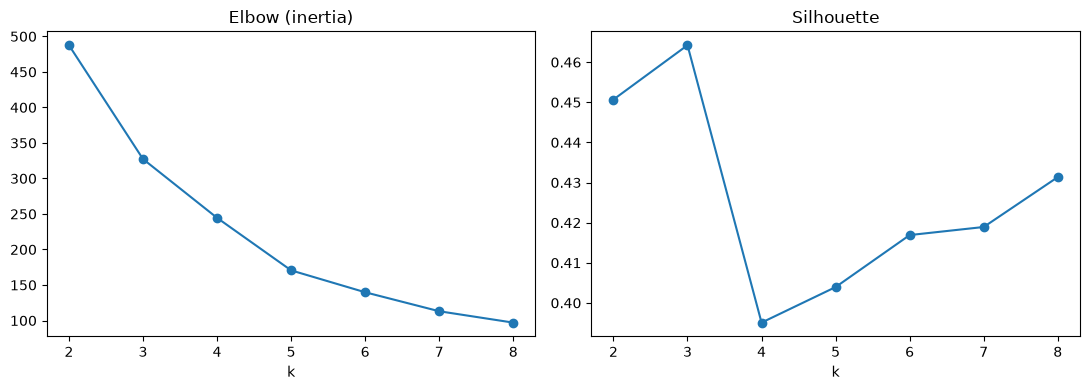

[0.451, 0.464, 0.395, 0.404, 0.417, 0.419, 0.431]


In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

X = StandardScaler().fit_transform(feat[cols])

ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertias, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sils, marker="o"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print([round(s, 3) for s in sils])

In [20]:
print(feat.sort_values("cfr", ascending=False)[["population", "cases", "deaths", "cfr"]].head(5))
print(feat.sort_values("cases_100k")[["population", "cases", "deaths", "cases_100k"]].head(5))

             population    cases  deaths       cfr
pays                                              
North Korea    26232530      1.0     6.0  6.000000
Yemen          37140234  11945.0  2159.0  0.180745
Sudan          48066930  63829.0  5017.0  0.078601
Syria          21628837  57467.0  3164.0  0.055058
Somalia        17271435  27324.0  1361.0  0.049810
             population    cases  deaths  cases_100k
pays                                                
North Korea    26232530      1.0     6.0    0.003812
Yemen          37140234  11945.0  2159.0   32.161887
Niger          24502145   9508.0   315.0   38.804766
Chad           17828274   7679.0   194.0   43.072033
Tanzania       62830410  42906.0   846.0   68.288588


In [21]:
feat2 = feat[(feat["cfr"] <= 1) & (feat["cases_100k"] > 1)].copy()
print(len(feat2))

X = StandardScaler().fit_transform(feat2[cols])
K = 3                      # revisit after rerunning the elbow/silhouette cell on feat2
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
feat2["cluster"] = km.labels_
feat2.groupby("cluster")[cols].mean().round(2).join(feat2["cluster"].value_counts().rename("n"))

158


,cases_100k,deaths_100k,cfr,peak_week_100k,peak_day,n
cluster,,,,,,
0,1619.73,22.09,0.02,103.98,585.88,73
1,45452.58,212.13,0.00,3498.44,756.24,33
2,15313.59,220.38,0.02,918.32,759.13,52


         cases_100k  deaths_100k     cfr  peak_week_100k  peak_day
cluster                                                           
0          523.6221      10.4375  0.0156         39.7947     616.0
1        46212.3522     221.2127  0.0047       3154.1609     745.0
2        14223.4067     185.8698  0.0136        868.9373     741.0
cluster                        2
cluster_name      High mortality
cases_100k            9554.00305
deaths_100k           243.521564
cfr                     0.025489
peak_week_100k        547.904844
peak_day                     731
Name: Tunisia, dtype: object
0 ['Afghanistan', 'Algeria', 'Angola', 'Bangladesh', 'Benin', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Central African Republic', 'Chad', 'Congo', "Cote d'Ivoire", 'Cuba', 'Democratic Republic of Congo']
1 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'France', 'Georgia', 'Germany', 'Greece', 'Hong Kong', 'Ireland', 'Israel']
2 ['Albania', 'Argenti

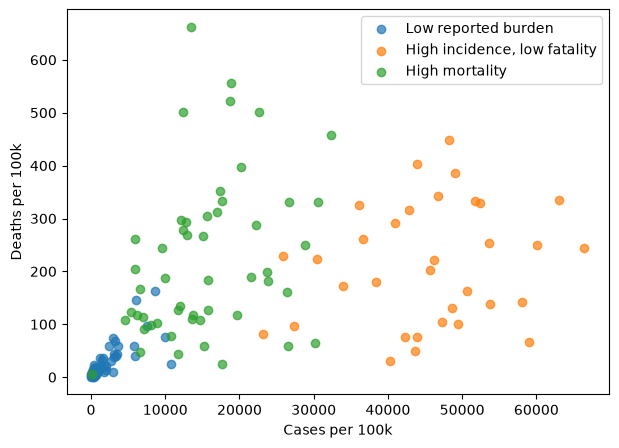

In [22]:
names = {0: "Low reported burden", 1: "High incidence, low fatality", 2: "High mortality"}
feat2["cluster_name"] = feat2["cluster"].map(names)

print(feat2.groupby("cluster")[cols].median().round(4))
print(feat2.loc["Tunisia", ["cluster", "cluster_name"] + cols])
for c in sorted(feat2["cluster"].unique()):
    print(c, sorted(feat2.index[feat2["cluster"] == c])[:15])

plt.figure(figsize=(7, 5))
for c, g in feat2.groupby("cluster"):
    plt.scatter(g["cases_100k"], g["deaths_100k"], label=names[c], alpha=0.7)
plt.xlabel("Cases per 100k"); plt.ylabel("Deaths per 100k"); plt.legend(); plt.show()

In [23]:
names = {0: "Low reported burden",
         1: "High incidence, low case fatality",
         2: "Moderate incidence, high case fatality"}
feat2["cluster_name"] = feat2["cluster"].map(names)
feat2.to_csv("../data/country_clusters.csv")
print(feat2["cluster_name"].value_counts())

cluster_name
Low reported burden                       73
Moderate incidence, high case fatality    52
High incidence, low case fatality         33
Name: count, dtype: int64


In [24]:
X2 = StandardScaler().fit_transform(feat2[cols])
print([round(silhouette_score(X2, KMeans(n_clusters=k, n_init=20, random_state=42).fit(X2).labels_), 3) for k in range(2, 9)])

[0.416, 0.309, 0.377, 0.344, 0.327, 0.334, 0.35]


In [25]:
for K in (2, 3, 4):
    km_k = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X2)
    tmp = feat2[cols].copy()
    tmp["cluster"] = km_k.labels_
    print(f"--- k={K} ---")
    print(tmp.groupby("cluster")[cols].median().round(3).join(tmp["cluster"].value_counts().rename("n")))

print([round(KMeans(n_clusters=k, n_init=20, random_state=42).fit(X2).inertia_, 1) for k in range(2, 9)])

--- k=2 ---
         cases_100k  deaths_100k    cfr  peak_week_100k  peak_day    n
cluster                                                               
0          1371.995       18.872  0.016         110.709     708.0  100
1         33120.034      250.143  0.007        2331.070     742.0   58
--- k=3 ---
         cases_100k  deaths_100k    cfr  peak_week_100k  peak_day   n
cluster                                                              
0           523.622       10.438  0.016          39.795     616.0  73
1         46212.352      221.213  0.005        3154.161     745.0  33
2         14223.407      185.870  0.014         868.937     741.0  52
--- k=4 ---
         cases_100k  deaths_100k    cfr  peak_week_100k  peak_day   n
cluster                                                              
0          1187.459       16.856  0.014          76.459     707.0  93
1         16318.484      300.715  0.020         907.190     736.0  26
2            32.162        5.813  0.181           

In [26]:
feat3 = feat[(feat["cfr"] <= 0.10) & (feat["cases_100k"] > 1)].copy()
print(len(feat3), "countries; removed:", sorted(set(feat.index) - set(feat3.index)))

X3 = StandardScaler().fit_transform(feat3[cols])
print("silhouette k=2..8:",
      [round(silhouette_score(X3, KMeans(n_clusters=k, n_init=20, random_state=42).fit(X3).labels_), 3) for k in range(2, 9)])

for K in (2, 3, 4):
    labels = KMeans(n_clusters=K, n_init=20, random_state=42).fit_predict(X3)
    tmp = feat3[cols].copy()
    tmp["cluster"] = labels
    print(f"--- k={K} ---")
    print(tmp.groupby("cluster")[cols].median().round(3).join(tmp["cluster"].value_counts().rename("n")))

157 countries; removed: ['North Korea', 'Yemen']
silhouette k=2..8: [0.4, 0.391, 0.357, 0.388, 0.351, 0.32, 0.325]
--- k=2 ---
         cases_100k  deaths_100k    cfr  peak_week_100k  peak_day   n
cluster                                                              
0         33120.034      250.143  0.007        2331.070     742.0  58
1          1399.330       19.740  0.015         121.917     709.0  99
--- k=3 ---
         cases_100k  deaths_100k    cfr  peak_week_100k  peak_day   n
cluster                                                              
0         43748.454      199.979  0.005        2930.910     744.0  40
1          1371.995       17.783  0.013         110.709     708.0  90
2         12894.140      292.731  0.023         666.087     736.0  27
--- k=4 ---
         cases_100k  deaths_100k    cfr  peak_week_100k  peak_day   n
cluster                                                              
0           463.490       12.422  0.022          37.028     490.5  28
1        

In [27]:
km = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X3)
feat3["cluster"] = km.labels_
med = feat3.groupby("cluster")["cases_100k"].median()
low, high = med.idxmin(), med.idxmax()
mid = [c for c in med.index if c not in (low, high)][0]
names = {low: "Low reported burden",
         high: "High incidence, low case fatality",
         mid: "Moderate incidence, high mortality"}
feat3["cluster_name"] = feat3["cluster"].map(names)
feat3.to_csv("../data/country_clusters.csv")
print(feat3["cluster_name"].value_counts())
print(feat3.loc["Tunisia", ["cluster_name"] + cols])

cluster_name
Low reported burden                   90
High incidence, low case fatality     40
Moderate incidence, high mortality    27
Name: count, dtype: int64
cluster_name      Moderate incidence, high mortality
cases_100k                                9554.00305
deaths_100k                               243.521564
cfr                                         0.025489
peak_week_100k                            547.904844
peak_day                                         731
Name: Tunisia, dtype: object
